# Homework 4 — Evaluation (Lead Scoring)

This notebook works through the Module 4 homework: evaluating a binary classifier
with **ROC AUC, precision, recall, F1, threshold sweeps, and 5-fold cross-validation**.

**Dataset:** 5,000 leads. The target is `converted` — did the lead sign up?

**What you will practice**

- using ROC AUC to rank features (and why a feature can have AUC below 0.5)
- turning a table of mixed types into a model-ready matrix with `DictVectorizer`
- computing precision, recall, and F1 at every threshold
- measuring how stable a score is with `KFold` cross-validation
- tuning the regularization strength `C`

Every question has four parts: **the idea**, **the code**, **the result**, and
**why that answer is correct**.

> Homework page: <https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/04-evaluation/homework.md>

## How to use these notes

This notebook is both a homework solution and a set of study notes. Each question
has four layers:

1. **The idea** — the concept in plain language.
2. **The code** — the smallest implementation that answers the question.
3. **The result** — the number and how to read it.
4. **The why** — intuition, caveats, and what would change the answer.

If you are revising later, the **idea** and **why** sections are the ones to
re-read; the code is there to make them concrete.

### The evaluation workflow

A classifier produces probabilities. To judge it you need:

- a **threshold** to turn probabilities into yes/no decisions,
- a **confusion matrix** to count the four outcomes,
- **threshold-dependent metrics** derived from that matrix (precision, recall, F1),
- **threshold-free views** of ranking quality (ROC-AUC, PR-AUC),
- **cross-validation** to check that the score is not a fluke of one split.

The homework walks through exactly those pieces, in that order.

### Reproducibility

- Every random operation uses `random_state=1`.
- The dataset is pinned at `data/course_lead_scoring_2026.csv`.
- Run the notebook top-to-bottom: later cells reuse variables defined earlier.


## 1. Setup

We need pandas/numpy for the table, matplotlib for the plots, and scikit-learn for
the split, encoding, model, metrics, and cross-validation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score

## 2. Load and prepare the data

The dataset has four categorical columns, four numerical columns, and the target:

| Type | Columns |
|---|---|
| Categorical | `lead_source`, `industry`, `employment_status`, `location` |
| Numerical | `annual_income`, `number_of_courses_viewed`, `interaction_count`, `lead_score` |
| Target | `converted` (1 = signed up, 0 = did not) |

The homework explicitly checks for missing values first. We follow its rules:
**categorical → `"NA"`**, **numerical → `0.0`**.

In [2]:
df = pd.read_csv("../data/course_lead_scoring_2026.csv")

print("shape:", df.shape)
df.head()

shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = ["annual_income", "number_of_courses_viewed", "interaction_count", "lead_score"]
target = "converted"

print("Missing values before:")
print(df.isnull().sum())

# Categoricals: "NA" becomes its own category, so no information is silently lost.
for col in categorical:
    df[col] = df[col].fillna("NA")

# Numericals: 0.0 is the homework's sentinel. It is not always the best real-world
# choice, but we follow the assignment exactly.
for col in numerical:
    df[col] = df[col].fillna(0.0)

print("\nMissing values after:", df.isnull().sum().sum())

Missing values before:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

Missing values after: 0


**Why this matters:** `roc_auc_score` and logistic regression cannot handle NaN.
Filling categoricals with the string `"NA"` makes missingness visible to the
one-hot encoder; filling numbers with `0.0` is a simple sentinel. In a real project
you might use a median imputer plus a missing-value indicator instead — but the
homework asks for these exact rules.

### How balanced is the target?

Before choosing a metric, look at the **base rate**. If about 58% of leads convert,
a model that always says "converted" is already 58% accurate. Accuracy would call
that decent; AUC would call it useless (0.5). This is the **accuracy paradox** that
motivates the whole homework.

The code below shows the class counts and the majority-class baseline.

In [4]:
counts = df[target].value_counts().sort_index()
rates = df[target].value_counts(normalize=True).sort_index()

print(counts)
print("\nrates:", rates.round(3).to_dict())
print("majority-class accuracy:", round(rates.max(), 3))

converted
0    2117
1    2883
Name: count, dtype: int64

rates: {0: 0.423, 1: 0.577}
majority-class accuracy: 0.577


## 3. Split the data

Use exactly the calls from the homework:

```python
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
```

That gives **3,000 train / 1,000 validation / 1,000 test** rows.

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train[target].values
y_val = df_val[target].values

print(len(df_train), len(df_val), len(df_test))
print("train positive rate:", round(y_train.mean(), 3))
print("validation positive rate:", round(y_val.mean(), 3))

3000 1000 1000
train positive rate: 0.576
validation positive rate: 0.586


## Why three sets, not two?

- **train** — fit the model's weights.
- **validation** — make choices: threshold, `C`, feature set. It is allowed to
  influence the model.
- **test** — a final, one-time estimate. Nothing may be tuned on it.

If you choose the threshold on test (a common mistake), the test score becomes
optimistic: you have used the test set to make a decision. That is why the homework
never asks you to tune on test. All model comparisons here are on validation or
inside cross-validation.

None of the homework questions asks for a final test score, so `df_test` stays
untouched here. That is deliberate: the test set is only useful when you have a
frozen model and a final decision to report.


## Interlude: what ROC AUC actually measures

For a fixed threshold, the confusion matrix gives two useful rates:

- **TPR / recall** = `TP / (TP + FN)`: of the real positives, how many did we catch?
- **FPR** = `FP / (FP + TN)`: of the real negatives, how many did we falsely flag?

The **ROC curve** plots TPR (y) against FPR (x) over every possible threshold. The
**area under that curve** is AUC. A very useful interpretation:

> Pick a random positive and a random negative. AUC is the probability that the
> model gives the positive a higher score.

Consequences:

- AUC is **threshold-free** — it summarizes ranking, not one operating point.
- AUC is **scale-free** for ranking — only the order of scores matters.
- AUC says nothing about **calibration** (whether 0.8 really means 80%).
- When positives are rare, ROC-AUC can look optimistic; **PR-AUC** is often more
  informative.

A single feature can also be used as a score — that is exactly what Question 1 does.

## Question 1 — ROC AUC feature importance

**Idea.** A model does not have to be a full pipeline to be scored. Any numeric
column can be used directly as a score: higher value = more likely to be positive.
`roc_auc_score(y, feature)` measures how well that single column ranks positives
above negatives.

- AUC = 0.5 → the feature is useless (random ranking).
- AUC > 0.5 → higher feature values tend to mean positive.
- AUC < 0.5 → higher values tend to mean negative; **negating the feature** flips
  the ranking, and the new AUC becomes `1 - old AUC`.

We compute this on the **training set**, as the homework says.

In [6]:
auc_by_feature = {}

for col in numerical:
    raw_auc = roc_auc_score(y_train, df_train[col])

    if raw_auc < 0.5:
        # The feature is negatively correlated with the target. Negating it turns
        # the relationship positive; its AUC becomes 1 - raw_auc.
        corrected_auc = roc_auc_score(y_train, -df_train[col])
        direction = "negated"
    else:
        corrected_auc = raw_auc
        direction = "as-is"

    auc_by_feature[col] = corrected_auc
    print(f"{col:28s} raw={raw_auc:.3f}  corrected={corrected_auc:.3f}  ({direction})")

auc_series = pd.Series(auc_by_feature).sort_values(ascending=False)
auc_series

annual_income                raw=0.608  corrected=0.608  (as-is)
number_of_courses_viewed     raw=0.723  corrected=0.723  (as-is)
interaction_count            raw=0.765  corrected=0.765  (as-is)
lead_score                   raw=0.788  corrected=0.788  (as-is)


lead_score                  0.788225
interaction_count           0.764920
number_of_courses_viewed    0.722989
annual_income               0.608198
dtype: float64

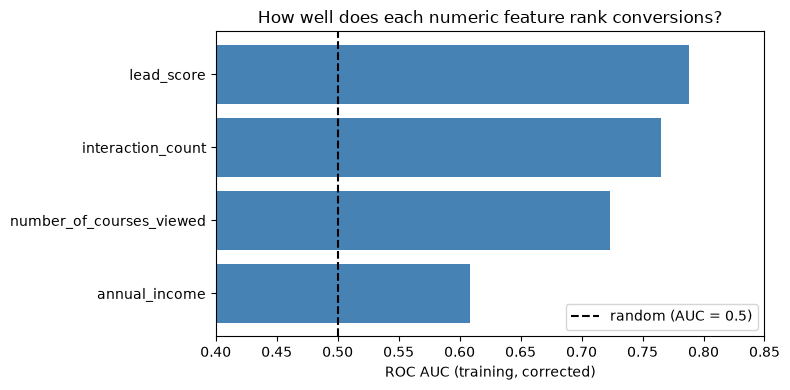

In [7]:
plt.figure(figsize=(8, 4))
plt.barh(auc_series.index[::-1], auc_series.values[::-1], color="steelblue")
plt.axvline(0.5, color="black", linestyle="--", label="random (AUC = 0.5)")
plt.xlim(0.4, 0.85)
plt.xlabel("ROC AUC (training, corrected)")
plt.title("How well does each numeric feature rank conversions?")
plt.legend()
plt.tight_layout()
plt.show()

**Answer: `lead_score`**, with AUC ≈ **0.788**.

| Feature | Best AUC |
|---|---|
| `lead_score` | **0.788** |
| `interaction_count` | 0.765 |
| `number_of_courses_viewed` | 0.723 |
| `annual_income` | 0.608 |

None of the four had a raw AUC below 0.5, so no negation was needed on this
dataset. The code still handles it, because another dataset may behave differently.

### What univariate AUC does and does not tell you

- It is a **quick filter**: a feature with AUC 0.79 is worth a closer look.
- It ignores **interactions**: two weak features can be strong together.
- It ignores **calibration**: a feature can rank well without being a probability.
- It is **univariate**: it says nothing about how the feature behaves once the other
  features are in the model.
- It is **descriptive, not causal**: a high AUC means the feature is associated with
  the outcome, not that changing it would change the outcome.

Use it to rank features for a first pass; then let the model decide how much each
one actually contributes.

## Interlude: logistic regression in one paragraph

Logistic regression is a linear model followed by a sigmoid:

$$z = w_0 + w_1 x_1 + \dots + w_n x_n$$

$$P(y=1 \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}}$$

The weights are chosen to maximize the likelihood of the observed labels
(equivalently, minimize log loss). `C` controls **L2 regularization**: it penalizes
large weights. `liblinear` is a small, reliable solver for this dataset size.

The output is a probability per row; a threshold turns it into 0/1. `DictVectorizer`
is the bridge from a pandas table to the numeric matrix `X`: categorical strings
become one-hot columns, numeric columns pass through unchanged.

## Question 2 — Train the model

**Idea.** `DictVectorizer` takes a list of dictionaries (one per row) and:

- one-hot encodes categorical strings (`lead_source=referral` → a 0/1 column),
- passes numeric columns through unchanged.

Then we fit `LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)` exactly
as the homework specifies, and compute AUC on the **validation** set.

We pass `sparse=False` so the encoded matrix is a regular dense array, which is
easier to inspect; the default sparse matrix would also work with `liblinear`.

> `C` is the inverse regularization strength: smaller `C` = stronger regularization.
> We keep `C=1.0` here and tune it in Question 6.

In [8]:
# Fit the encoder on TRAIN only; reuse it for validation/test.
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train.drop(columns=[target]).to_dict(orient="records"))
X_val = dv.transform(df_val.drop(columns=[target]).to_dict(orient="records"))

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)

# Predict probabilities, not hard labels: AUC needs the ranking.
y_pred = model.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_pred)

print("encoded features:", len(dv.get_feature_names_out()))
print(f"validation AUC: {val_auc:.3f}")

encoded features: 28
validation AUC: 0.732


### What did the model learn?

After one-hot encoding, columns have names like `lead_source=referral`; numeric
columns keep their names. Pairing each name with its coefficient shows which signals
push the prediction up or down:

- **positive coefficient** → pushes toward `converted`,
- **negative coefficient** → pushes away from `converted`,
- **magnitude** depends on feature scale, so use this for direction and rough
  relative importance, not as a strict ranking.

These are associations learned from this dataset, not causal effects.

In [9]:
feature_names = dv.get_feature_names_out()
coefs = pd.Series(model.coef_[0], index=feature_names)

print("Top positive signals:")
print(coefs[coefs > 0].sort_values(ascending=False).head(8).round(3))

print("\nTop negative signals:")
print(coefs[coefs < 0].sort_values().head(8).round(3))

Top positive signals:
interaction_count             0.252
number_of_courses_viewed      0.105
employment_status=employed    0.033
lead_source=referral          0.027
lead_score                    0.019
lead_source=organic_search    0.013
industry=technology           0.012
dtype: float64

Top negative signals:
lead_source=paid_ads           -0.065
employment_status=student      -0.055
employment_status=unemployed   -0.047
lead_source=events             -0.041
industry=retail                -0.032
lead_source=social_media       -0.025
industry=education             -0.025
industry=healthcare            -0.024
dtype: float64


**Answer: 0.732.**

That is well above 0.5, so the model has real ranking ability. For context, this
dataset is about **58% positive**, so a "always predict converted" model would have
high accuracy but an AUC of 0.5 — useless at ranking. This is why the homework uses
AUC rather than accuracy.

### The model's ROC curve

Question 1 used individual features as scores. Now use the model's predicted
probabilities as the score. This is the same AUC as Question 2, but the curve shows
the whole trade-off instead of a single number.

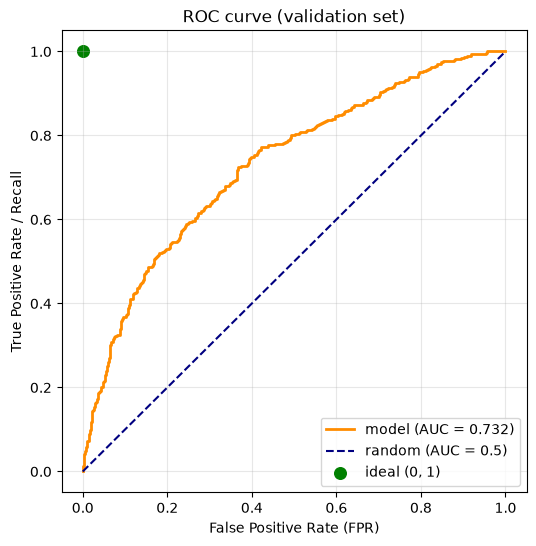

In [10]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_pred)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"model (AUC = {val_auc:.3f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--",
         label="random (AUC = 0.5)")
plt.scatter([0], [1], color="green", s=70, label="ideal (0, 1)")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate / Recall")
plt.title("ROC curve (validation set)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

### A concrete threshold: 0.5

Before sweeping thresholds, look at the default. At 0.5:

- **TP** = converted leads we flagged,
- **FP** = leads we flagged that did not convert,
- **FN** = converted leads we missed,
- **TN** = non-converted leads we correctly ignored.

Those four counts are the raw material for every threshold-based metric. Precision,
recall, and F1 below are exactly what Question 3 and Question 4 sweep over. At 0.5
the model is recall-heavy (precision 0.644, recall 0.906): it flags aggressively,
which is why moving the threshold upward is worth exploring.

In [11]:
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

decision_50 = (y_pred >= 0.5).astype(int)
cm = confusion_matrix(y_val, decision_50)
tn, fp, fn, tp = cm.ravel()

print("confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"precision = {precision_score(y_val, decision_50):.3f}")
print(f"recall    = {recall_score(y_val, decision_50):.3f}")
print(f"F1        = {f1_score(y_val, decision_50):.3f}")

confusion matrix [[TN, FP], [FN, TP]]:
[[120 294]
 [ 55 531]]
TN=120  FP=294  FN=55  TP=531
precision = 0.644
recall    = 0.906
F1        = 0.753


## Question 3 — Precision and recall at every threshold

**Idea.** The model outputs a probability. To make a yes/no decision we pick a
**threshold**. Every threshold gives a different confusion matrix, and therefore
different precision and recall:

- **Precision** = of the leads we flagged, how many really converted? `TP / (TP + FP)`
- **Recall** = of the leads that really converted, how many did we flag? `TP / (TP + FN)`

Lower the threshold → flag more → recall rises, precision usually falls.
The homework asks for the threshold where the two curves **cross** (are closest),
ignoring thresholds where both are zero.

In [12]:
thresholds = np.arange(0.0, 1.01, 0.01)

rows = []
for t in thresholds:
    decision = (y_pred >= t).astype(int)
    rows.append({
        "threshold": round(float(t), 2),
        "precision": precision_score(y_val, decision, zero_division=0),
        "recall": recall_score(y_val, decision, zero_division=0),
    })

scores = pd.DataFrame(rows)

# Ignore thresholds where both metrics are zero (e.g. t = 1.0, where nothing is
# predicted positive). Among the rest, find where precision and recall are closest.
candidates = scores[(scores["precision"] > 0) | (scores["recall"] > 0)].copy()
candidates["abs_diff"] = (candidates["precision"] - candidates["recall"]).abs()
crossing = candidates.loc[candidates["abs_diff"].idxmin()]

print(crossing.to_dict())

{'threshold': 0.63, 'precision': 0.7327586206896551, 'recall': 0.7252559726962458, 'abs_diff': 0.007502647993409384}


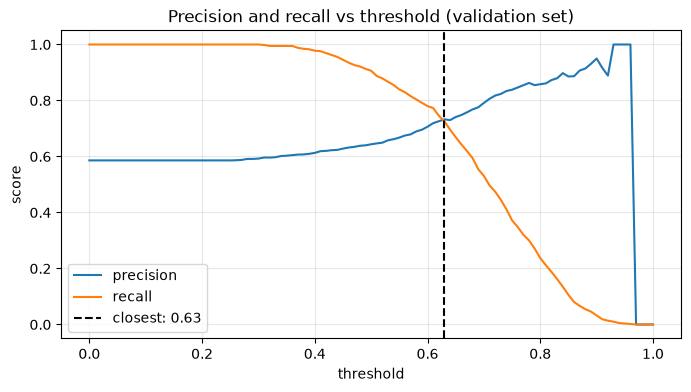

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(scores["threshold"], scores["precision"], label="precision")
plt.plot(scores["threshold"], scores["recall"], label="recall")
plt.axvline(crossing["threshold"], color="black", linestyle="--",
            label=f"closest: {crossing['threshold']:.2f}")
plt.xlabel("threshold")
plt.ylabel("score")
plt.title("Precision and recall vs threshold (validation set)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Answer: 0.63** (precision 0.733, recall 0.725, difference 0.0075).

The exact crossing often falls *between* two grid points, so the homework's rule is
to choose the threshold with the smallest absolute difference — not to demand an
exact equality. At 0.63 the model is roughly balanced between false alarms and
misses; that is a reasonable default before bringing in business costs.

### Why the curves cross, and why there is no single "best" threshold

As the threshold falls:

- more rows are predicted positive,
- TP and FP both increase,
- **recall rises**, **precision usually falls**.

The crossing point is where the two metrics are balanced, but **balance is not the
same as optimal**. The right threshold depends on the cost ratio
`cost(FP) / cost(FN)`:

- If a missed converter is worth $500 and a retention offer costs $20, you should
  tolerate many false positives and choose a threshold **below** the crossing.
- If false positives are expensive, choose **above** the crossing.

F1 implicitly assumes precision and recall are equally important. That is a modeling
choice, not a law of nature.

## Question 4 — F1 score

**Idea.** Precision and recall pull in opposite directions, so it helps to combine
them. **F1** is their harmonic mean:

$$
F_1 = 2 \cdot \frac{P \cdot R}{P + R}
$$

The harmonic mean punishes imbalance: if either precision or recall is near zero,
F1 is near zero too. We compute F1 at every threshold and take the maximum.

In [14]:
# F1 from the precision/recall columns. The denominator is nonzero for every
# candidate row, but np.where keeps the code safe at degenerate thresholds.
scores["f1"] = np.where(
    (scores["precision"] + scores["recall"]) > 0,
    2 * scores["precision"] * scores["recall"]
    / (scores["precision"] + scores["recall"]),
    0.0,
)

best_f1 = scores.loc[scores["f1"].idxmax()]
print(best_f1.to_dict())

{'threshold': 0.41, 'precision': 0.6190476190476191, 'recall': 0.9761092150170648, 'f1': 0.7576158940397352}


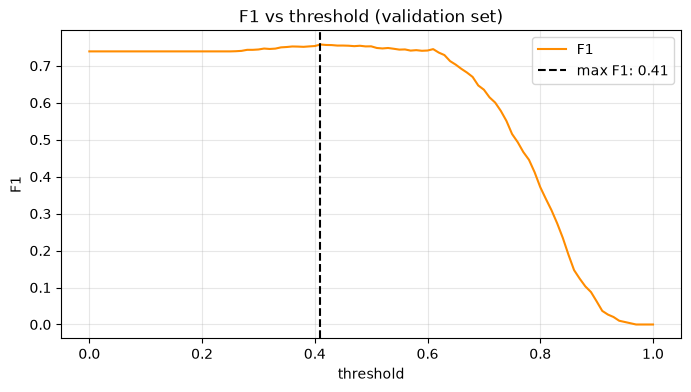

In [15]:
plt.figure(figsize=(8, 4))
plt.plot(scores["threshold"], scores["f1"], color="darkorange", label="F1")
plt.axvline(best_f1["threshold"], color="black", linestyle="--",
            label=f"max F1: {best_f1['threshold']:.2f}")
plt.xlabel("threshold")
plt.ylabel("F1")
plt.title("F1 vs threshold (validation set)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Answer: 0.41** (F1 0.758, precision 0.619, recall 0.976).

This is a deliberately lopsided operating point: the model flags almost everyone,
so recall is very high while precision is modest. That is what maximizes F1 here.
It is a useful reminder that "best F1" is not automatically the best business
choice — if false alarms are expensive, you would move the threshold higher.

### Beyond F1: the F-beta family

F1 is the harmonic mean with equal weight on precision and recall. The general form is:

$$F_\beta = (1+\beta^2)\frac{P R}{\beta^2 P + R}$$

- β < 1 → precision matters more,
- β > 1 → recall matters more,
- β = 1 → F1.

The **harmonic** mean (not the arithmetic mean) is what makes F1 strict: a high
precision cannot hide a low recall, and vice versa. The arithmetic mean would be
inflated by one strong number even when the other is weak.

## Interlude: how 5-fold cross-validation works

Split `df_full_train` into five equal folds (here 800 rows each):

| round | train on | validate on |
|---|---|---|
| 1 | folds 2, 3, 4, 5 | fold 1 |
| 2 | folds 1, 3, 4, 5 | fold 2 |
| 3 | folds 1, 2, 4, 5 | fold 3 |
| 4 | folds 1, 2, 3, 5 | fold 4 |
| 5 | folds 1, 2, 3, 4 | fold 5 |

Every row is validated exactly once. The five scores estimate how much the result
depends on the particular split.

- `shuffle=True` randomizes the row order before folding. This matters if the data
  is sorted (e.g. by date or by target).
- `random_state=1` makes the folds reproducible.
- `KFold` does **not** preserve the class ratio in each fold. For imbalanced data,
  `StratifiedKFold` is usually a better default; the homework explicitly asks for
  `KFold`, so we use it.

## Question 5 — 5-fold cross-validation

**Idea.** A single train/validation split can be lucky. **K-fold CV** splits
`df_full_train` into 5 parts; each part is used for validation exactly once, and the
other 4 parts are used for training. We get five AUC scores, then look at their
**mean** (quality) and **standard deviation** (stability).

Two important details:

- The homework says `KFold`, **not** `StratifiedKFold`. We follow it exactly.
- Fit the `DictVectorizer` **inside each fold** on that fold's training data only.
  Fitting it once on all data would leak validation information into preprocessing.

In [16]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)


def cv_auc(C=1.0):
    """Return the 5 validation AUC scores for a given regularization strength."""
    fold_aucs = []

    for train_idx, val_idx in kf.split(df_full_train):
        tr = df_full_train.iloc[train_idx]
        va = df_full_train.iloc[val_idx]

        # Fresh encoder per fold: no information from the validation fold.
        dv_fold = DictVectorizer(sparse=False)
        X_tr = dv_fold.fit_transform(tr.drop(columns=[target]).to_dict(orient="records"))
        X_va = dv_fold.transform(va.drop(columns=[target]).to_dict(orient="records"))

        m = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
        m.fit(X_tr, tr[target].values)

        pred = m.predict_proba(X_va)[:, 1]
        fold_aucs.append(roc_auc_score(va[target].values, pred))

    return np.array(fold_aucs)


fold_aucs = cv_auc()
for i, auc in enumerate(fold_aucs, start=1):
    print(f"fold {i}: AUC = {auc:.3f}")

print(f"\nmean AUC = {fold_aucs.mean():.3f}")
print(f"std AUC  = {fold_aucs.std():.3f}")

fold 1: AUC = 0.731
fold 2: AUC = 0.730
fold 3: AUC = 0.736
fold 4: AUC = 0.741
fold 5: AUC = 0.721

mean AUC = 0.732
std AUC  = 0.007


### Mean, standard deviation, and standard error

- **mean** — the best single estimate of performance.
- **std** — spread of the five fold scores: how sensitive the result is to the split.
- **standard error** — `std / sqrt(k)`: uncertainty of the mean estimate.

A rough 95% interval is `mean ± 1.96 * standard error`. It is not a substitute for a
proper repeated CV or a held-out test, but it makes the uncertainty concrete.

In [17]:
n_folds = len(fold_aucs)
se = fold_aucs.std(ddof=1) / np.sqrt(n_folds)
ci_low = fold_aucs.mean() - 1.96 * se
ci_high = fold_aucs.mean() + 1.96 * se

print(f"mean AUC       = {fold_aucs.mean():.3f}")
print(f"std (ddof=0)   = {fold_aucs.std():.3f}")
print(f"std (ddof=1)   = {fold_aucs.std(ddof=1):.3f}")
print(f"standard error = {se:.4f}")
print(f"~95% interval  = [{ci_low:.3f}, {ci_high:.3f}]")

mean AUC       = 0.732
std (ddof=0)   = 0.007
std (ddof=1)   = 0.008
standard error = 0.0034
~95% interval  = [0.725, 0.738]


**Answer: 0.007** (fold AUCs: 0.731, 0.730, 0.736, 0.741, 0.721).

The folds are close together, so the single-split validation AUC of 0.732 was a fair
estimate — not a lucky split. Note the two conventions for standard deviation:
`np.std` (population, `ddof=0`) gives **0.007**, while pandas' `.std()` (sample,
`ddof=1`) gives **0.008**. The homework's options use the population value, which is
what `np.std` returns by default.

## Interlude: what `C` does mathematically

Logistic regression with L2 regularization minimizes:

$$\text{loss} = \text{log loss} + \frac{1}{2C}\sum_j w_j^2$$

Equivalently, with `lambda = 1/C`, the penalty is `lambda * sum(w^2)`:

- small `C` → large `1/C` → strong penalty → weights shrink toward 0,
- large `C` → weak penalty → weights can grow to fit the training data.

This is the bias-variance trade-off: strong regularization reduces variance but can
introduce bias (underfitting). `C` is selected by cross-validation, never by the
test set.

**Scale caveat:** the penalty applies to the raw coefficients, so unscaled features
(like `annual_income`, in the tens of thousands) are penalized differently from small
ones. Standardizing numeric features before a regularized model often changes which
`C` is best. The homework does not standardize, so we follow its setup exactly.

## Question 6 — Hyperparameter tuning

**Idea.** `C` controls regularization:

- **Small C** → stronger regularization → simpler model; can underfit.
- **Large C** → weaker regularization → more flexible; can overfit.

We try `[0.000001, 0.001, 1]` with the same `KFold` setup and compare mean AUC
(and std for stability). Tie-break rules from the homework: lower std first, then
smaller `C`.

In [18]:
results = []

for C in [0.000001, 0.001, 1]:
    aucs = cv_auc(C)
    results.append({
        "C": f"{C:g}",
        "mean AUC": aucs.mean(),
        "std AUC": aucs.std(),
    })

results_df = pd.DataFrame(results).round(3)
results_df

,C,mean AUC,std AUC
0,1e-06,0.617,0.019
1,0.001,0.749,0.010
2,1,0.732,0.007


### What strong regularization does to the weights

If `C` is tiny, the penalty dominates and the coefficients are pushed toward zero;
the model predicts something close to the base rate for everyone. The code below
fits on the full training set for each `C` and prints the largest absolute
coefficient. Watch it shrink as regularization gets stronger.

The loop starts at the smallest `C` (strongest penalty), so the output runs from
strongest to weakest regularization. Reading it from top to bottom, the weights grow
as the penalty is relaxed.


In [19]:
dv_full = DictVectorizer(sparse=False)
X_full = dv_full.fit_transform(
    df_full_train.drop(columns=[target]).to_dict(orient="records")
)

for C in [0.000001, 0.001, 1]:
    m = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    m.fit(X_full, df_full_train[target].values)
    print(f"C={C:.6g}: max|coef| = {np.abs(m.coef_).max():.4f}")

C=1e-06: max|coef| = 0.0017
C=0.001: max|coef| = 0.2147
C=1: max|coef| = 0.2593


**Answer: C = 0.001**, with mean AUC ≈ 0.749 (std 0.010).

| C | Mean AUC | Std |
|---|---|---|
| 0.000001 | 0.617 | 0.019 |
| **0.001** | **0.749** | 0.010 |
| 1 | 0.732 | 0.007 |

Two lessons:

1. **Too much regularization hurts.** `C=1e-6` shrinks the weights so hard that the
   model underfits (mean AUC 0.617, far below the 0.732–0.749 of the other settings).
2. **Bigger is not always better.** `C=1` is less regularized than `C=0.001` and its
   mean AUC is lower, even though its fold-to-fold std is slightly smaller. The
   homework prioritizes **mean AUC**, so `C=0.001` wins.

## Common pitfalls

1. **Forgetting to fill missing values** → `roc_auc_score` and `LogisticRegression`
   raise an error on NaN.
2. **Filling with the wrong type** → numeric columns must stay numeric; do not put
   the string `"NA"` into a numeric column.
3. **Fitting `DictVectorizer` on all data before splitting** → leakage; fit it on
   the training part (or inside each CV fold).
4. **Tuning the threshold or `C` on test** → optimistic score; use validation or CV.
5. **Using accuracy on an imbalanced target** → the majority-class baseline can look
   good while the model is useless; use AUC, precision, recall, and F1.
6. **Calling `precision_score` without `zero_division=0`** at thresholds with no
   positive predictions → warnings and undefined values.
7. **Comparing std across different `k`** → the standard deviation is not directly
   comparable; standard error is.
8. **Ignoring feature scale with regularization** → the L2 penalty is not
   scale-invariant.
9. **Assuming `KFold` is stratified** → for imbalanced data, consider
   `StratifiedKFold`.
10. **Reporting a single CV number** → report mean and std (and ideally the folds).

## If your numbers do not match the options

Work through these in order:

| Symptom | Likely cause |
|---|---|
| Error about NaN | missing values not filled |
| AUC around 0.5 for everything | wrong target column, or labels inverted |
| Q1 answer is not `lead_score` | AUC computed on the wrong split, or negation applied incorrectly |
| Q2 differs by a few points | vectorizer fit on train+val, or a different `solver` |
| Q3/Q4 threshold shifted | different threshold grid, or rows dropped because of `zero_division` warnings |
| Q5 std slightly different | `np.std` (ddof=0) vs pandas `.std()` (ddof=1) |
| Q6 picks `C=1` | different `KFold` seed, or tuning on a single split |

## Self-check questions

Try these without looking at the answers:

1. Why can a feature have AUC 0.39, and what does negating it do?
2. Why is accuracy a bad headline metric for this dataset?
3. At a lower threshold, which of precision/recall rises, and why?
4. Why is the harmonic mean used for F1 instead of the arithmetic mean?
5. Why must the vectorizer be fit inside each CV fold?
6. What does a small `C` do to the coefficients?
7. If two `C` values have the same mean AUC, how does the homework break the tie?
8. Why is `KFold` not automatically the best choice for imbalanced data?

## Answer summary

| Question | Answer | What it tests |
|---|---|---|
| 1 | **`lead_score`** (AUC 0.788) | ROC AUC as univariate feature ranking |
| 2 | **0.732** | `DictVectorizer` + logistic regression, validation AUC |
| 3 | **0.63** | precision/recall trade-off across thresholds |
| 4 | **0.41** | F1 as the harmonic mean of precision and recall |
| 5 | **0.007** | 5-fold `KFold` stability (std of AUC) |
| 6 | **0.001** | regularization strength chosen by mean CV AUC |

## What to remember

- **AUC is threshold-independent; precision/recall/F1 are not.** AUC compares
  ranking quality across all thresholds; the other three describe one operating
  point.
- **Accuracy is not enough on imbalanced data.** Always compare with a baseline
  (here, the positive rate) and look at AUC / precision / recall.
- **Preprocessing belongs inside each CV fold.** Fitting `DictVectorizer` on all
  data before splitting leaks validation information.
- **CV gives a distribution, not just a number.** Report mean **and** std.
- **`C` is inverse regularization.** Small `C` = stronger penalty; tune it with CV,
  don't guess.
- **The homework's exact settings matter.** `KFold` (not stratified),
  `solver="liblinear"`, `random_state=1`, threshold step 0.01, and the stated
  tie-break rules are all part of the expected answer.

## Glossary

- **Feature** — an input column.
- **Target / label** — the value being predicted (`converted`).
- **Score / probability** — model output before thresholding.
- **Threshold** — cutoff that turns a probability into 0/1.
- **TP / FP / FN / TN** — the four confusion-matrix cells.
- **Precision** — `TP / (TP + FP)`: purity of positive predictions.
- **Recall / TPR** — `TP / (TP + FN)`: coverage of real positives.
- **FPR** — `FP / (FP + TN)`: false alarms among real negatives.
- **Specificity / TNR** — `TN / (TN + FP)`: correctly ignored negatives.
- **F1** — harmonic mean of precision and recall.
- **ROC curve** — TPR vs FPR over all thresholds.
- **AUC** — area under the ROC curve; probability of ranking a random positive above
  a random negative.
- **PR curve / AP** — precision vs recall; average precision is its area.
- **Cross-validation** — rotate the validation fold so every row is validated once.
- **Regularization** — penalty on large weights; `C` is its inverse strength.
- **Leakage** — using validation/test information during training or preprocessing.

## Going further

- **Stratified K-fold** — keeps the class ratio in every fold; a better default for
  imbalanced data.
- **PR-AUC / average precision** — more informative than ROC-AUC when positives are
  rare.
- **Calibration** — check whether predicted probabilities match observed frequencies
  (reliability curve, Brier score).
- **Cost-sensitive threshold** — choose the cutoff from `cost(FP)` and `cost(FN)`,
  not from F1.
- **Feature scaling** — standardize numeric columns before regularized models, then
  re-tune `C`.
- **Class weights** — try `class_weight="balanced"`; it changes the precision/recall
  balance without changing the threshold.
- **Stronger models** — compare with `RandomForestClassifier` or
  `HistGradientBoostingClassifier`; tuning `C` only goes so far.
- **Repeated CV** — average over several `KFold` seeds to reduce split noise.